# IAU Projekt - fáza 2

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import statsmodels.stats as sm_stats
import sklearn
import category_encoders as ce

In [3]:
RANDOM_SEED = 1

### 2.1 Realizácia predspracovania dát

Nacitame data z readings a units a gateway. Z units budeme brať do úvahy atribúty year_commission, dutyClass, hours_service. Z gateways budeme brať do úvahy atribúť version_firmware, kedže koreloval s predikovanou premennou failure. Z readings odstránim atribút ts_cycle, ktorý označuje dátum merania, ktorý by nemal byť relevantný pre predikciu poruchy.

In [4]:
READINGS = "readings.csv"
readings_df = pd.read_csv(READINGS, delimiter="\t", parse_dates=["ts_cycle"], date_format="mixed")
readings_df["id_unit"] = readings_df["id_unit"].str.replace("U", "").astype(int)
readings_df.drop_duplicates(inplace=True)

UNITS = "units.csv"
units_df = pd.read_csv(UNITS, delimiter=",")
units_df["dutyClass"] = units_df["dutyClass"].str.strip()
units_df.replace({
    "1": "light", "L": "light",
    "N": "medium", "2": "medium", "normal": "medium", "med": "medium",
    "3": "heavy", "H": "heavy"
}, inplace=True)

GATEWAYS = "gateways.csv"
gateways_df = pd.read_csv(GATEWAYS, delimiter=";", parse_dates=["last_seen", "dateInstall"], date_format="mixed")
gateways_df = gateways_df.dropna(subset="id_unit")
gateways_df["id_unit"] = gateways_df.id_unit.astype(int)

# mergenem readings, units, gateways pomocou id_unit
readings_df = readings_df.drop(columns=["ts_cycle"])
units_cols = ["year_commission", "dutyClass", "hours_service"]
gateways_cols = ["version_firmware"]
main_df = (
    readings_df
    .merge(units_df[["id_unit"] + units_cols], on="id_unit", how="inner", validate="many_to_one",)
    .merge(gateways_df[["id_unit"] + gateways_cols], on="id_unit", how="inner", validate="many_to_one")
)
main_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14129 entries, 0 to 14128
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_unit            14129 non-null  int64  
 1   motor_current      14129 non-null  float64
 2   dpFilter           13590 non-null  float64
 3   temperature_oil    14129 non-null  float64
 4   reservoirPressure  14129 non-null  float64
 5   oilPressure        14129 non-null  float64
 6   rms_vibration      13575 non-null  float64
 7   Flowmeter          14129 non-null  float64
 8   humidityIntake     13448 non-null  float64
 9   failure            14129 non-null  int64  
 10  year_commission    14129 non-null  int64  
 11  dutyClass          14129 non-null  str    
 12  hours_service      13401 non-null  float64
 13  version_firmware   14129 non-null  str    
dtypes: float64(9), int64(3), str(2)
memory usage: 1.7 MB


### Rozdelenie na trenovacu a testovaciu množinu
Data náhodne rozdelime na trenovaciu a testovaciu množinu. 80% dat bude sluzit na trenovanie a 20% dat na testovanie.

In [5]:
train_df, test_df = sklearn.model_selection.train_test_split(main_df, test_size=0.2, random_state=RANDOM_SEED)

### Zadkovovanie kategorických premenných na numerické 
`dutyClass` - kedze tento atribut m jasné usporiadanie (light < medium < heavy) použijeme ordinal encoding

`version_firmware` - v dátach sú iba 3 rôzne verzie, preto použijeme one-hot encoding

In [6]:
mapping = [{'col': 'dutyClass', 'mapping': {'light': 1, 'medium': 2, 'heavy': 3}}]
ordinal_encoder = ce.OrdinalEncoder(mapping=mapping)
train_df = ordinal_encoder.fit_transform(train_df)
onehot_encoder = ce.OneHotEncoder(cols=["version_firmware"])
train_df = onehot_encoder.fit_transform(train_df)

In [7]:
train_df.info()

<class 'pandas.DataFrame'>
Index: 11303 entries, 9769 to 13349
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_unit             11303 non-null  int64  
 1   motor_current       11303 non-null  float64
 2   dpFilter            10886 non-null  float64
 3   temperature_oil     11303 non-null  float64
 4   reservoirPressure   11303 non-null  float64
 5   oilPressure         11303 non-null  float64
 6   rms_vibration       10849 non-null  float64
 7   Flowmeter           11303 non-null  float64
 8   humidityIntake      10755 non-null  float64
 9   failure             11303 non-null  int64  
 10  year_commission     11303 non-null  int64  
 11  dutyClass           11303 non-null  int64  
 12  hours_service       10721 non-null  float64
 13  version_firmware_1  11303 non-null  int64  
 14  version_firmware_2  11303 non-null  int64  
 15  version_firmware_3  11303 non-null  int64  
dtypes: float64(9), in

### Vyriešenie problemov identifikovaných v fáze 1
Hodnotu `-999` z atribútu `temperature_oil` prevedieme na chýbajúcu hodnotu. 
Počet chýbajúcich hodnôt pre `hours_service` je 728 z 14129 čo je 5.15%. Kedže ide o viac ako 5% použimeme **KNN imputer** na doplnenie chýbajúcich hodnôt.

In [8]:
train_df["temperature_oil"] = train_df["temperature_oil"].replace(-999, np.nan)

imputer = sklearn.impute.KNNImputer(n_neighbors=5)
train_df = pd.DataFrame(
    imputer.fit_transform(train_df), 
    columns=train_df.columns, 
    index=train_df.index
)

print("Pocet chybajucich hodnot po imputacii:", train_df.isnull().sum().sum())

Pocet chybajucich hodnot po imputacii: 0


Vykreslíme histogramy pre atribúty, po doplnění chýbajúcich hodnôt.

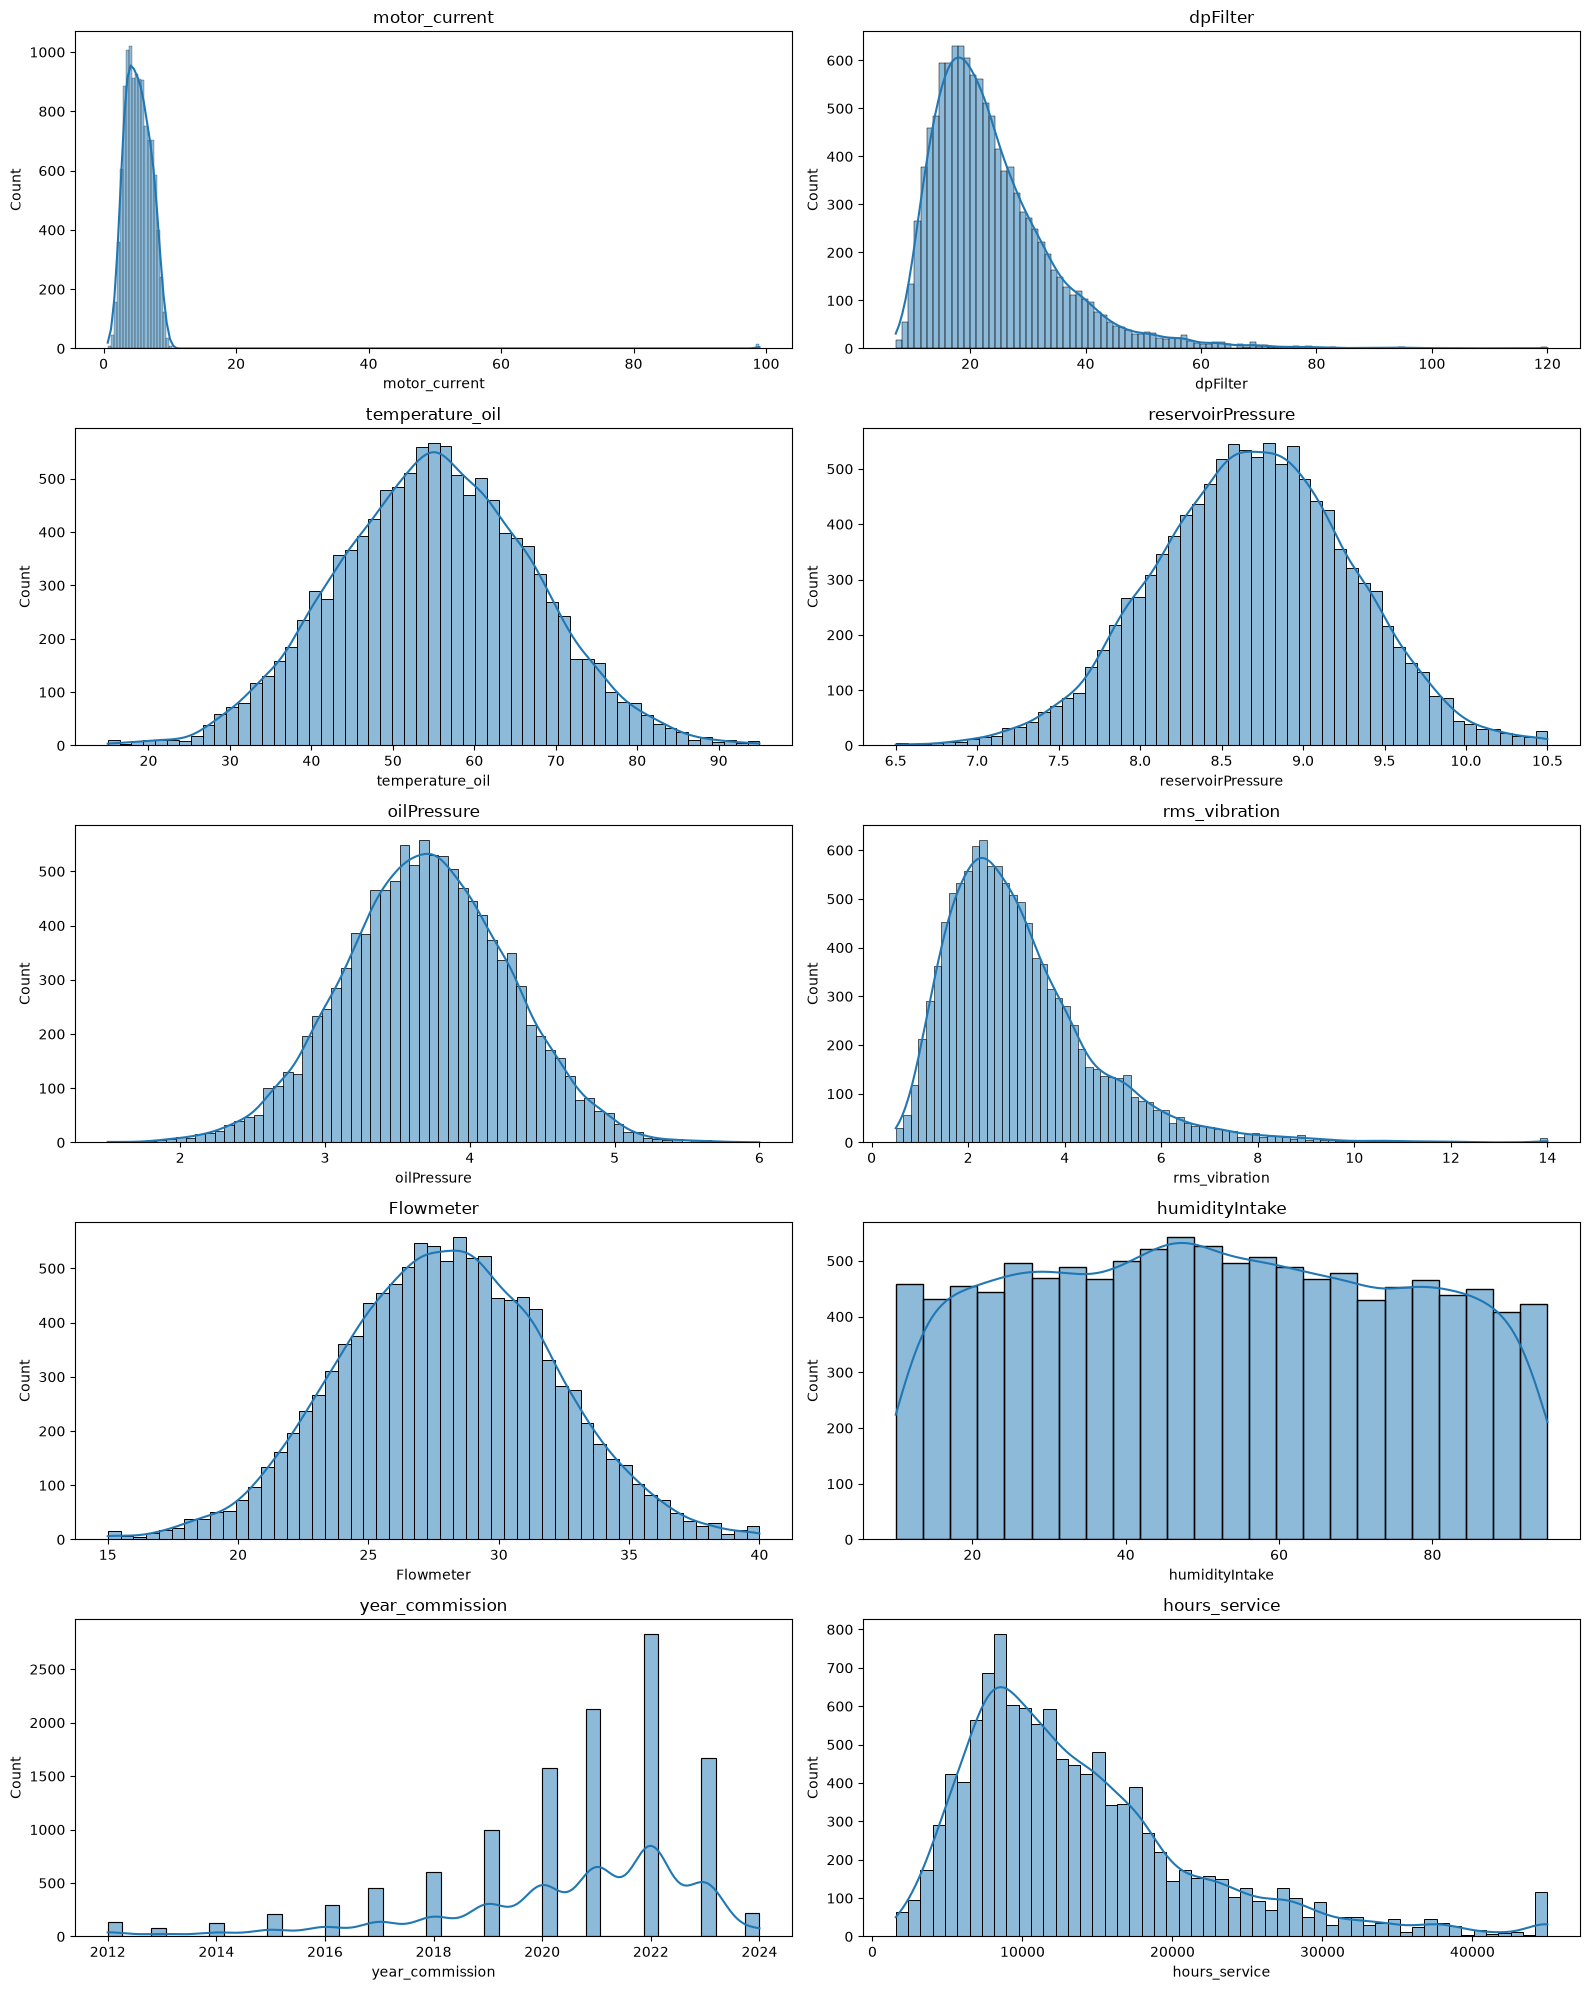

In [9]:
# Vygreslime histogramy pre pre všetky atribúty z train_df okrem id_unit, failure, dutyClass, version_firmware (1,2,3)

# Viem ze grafov bude 10, takze si vytvorim 10 subplots, 5x2
fig, axs = plt.subplots(5, 2, figsize=(16, 20))
attributes = [col for col in train_df.columns if col not in ["id_unit", "failure", "dutyClass", "version_firmware_1", "version_firmware_2", "version_firmware_3"]]
for i, attr in enumerate(attributes):
    row = i // 2
    col = i % 2
    sns.histplot(train_df[attr], ax=axs[row, col], kde=True)
    axs[row, col].set_title(attr)
    axs[row, col].set_xlabel(attr)
    axs[row, col].set_ylabel("Count")
fig.tight_layout()
plt.show()

### Odstránenie odľahlých hodnôt
Kedže pri odstranovaní odľahlých hodnôt prídeme o 2170 z 14129 záznamov, čo je 15.36% dat a pri winsorizacii nám na okrajoch distribúcie výrazne narastie počet záznamov. Najlepšie nám príde všetky odlahlé hodnoty zatial neodstraňovať ani nenahrádzat a neskôr použiť RobustScaler, ktorý je odolný voči odľahlým hodnotám.

In [10]:
def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# vypis odlahlých hodnôt motor current cez IQR
lower_bound, upper_bound = iqr_bounds(train_df["motor_current"])
print(f"Lower bound: {lower_bound}, Upper bound: {upper_bound}")
motor_current_outliers = train_df[(train_df["motor_current"] < lower_bound) | (train_df["motor_current"] > upper_bound)]
print("motor current outliers:", motor_current_outliers["motor_current"].values)

Lower bound: -0.5862474999999994, Upper bound: 10.953332499999998
motor current outliers: [99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99. 99.]


Všetky odľahlé hodnoty `motor_current` sú 99 čo je výrazne odlišné od upper bound 10.95. Preto ich nahradíme hodnotou upper bound 10.95.

In [11]:
train_df.loc[train_df["motor_current"] > upper_bound, "motor_current"] = upper_bound

Ostatné odľahlé hodnoty nie su jednoznačne chybné merania, a kedže ich je celkom veľa, tak ich nebudeme odstraňovať ani nahrádzať.

### Škalovanie atribútov

Máme podľa zadania použiť 2 metódy škálovania, a keďže sme sa v predošlom kroku rozhodli neodstrániť outlierov ani ich nenahradiť hraničnými hodnotami, **Normalizáciu** sme sa rozhodli nepoužiť, pretože si nevie tak dobre poradiť s outliermi. Vybrali sme si **RobustScaler**, ktorý je pre outlierov stvorený, a **StandardScaler**, ktorý by tiež mohol outlierov zvládnuť.

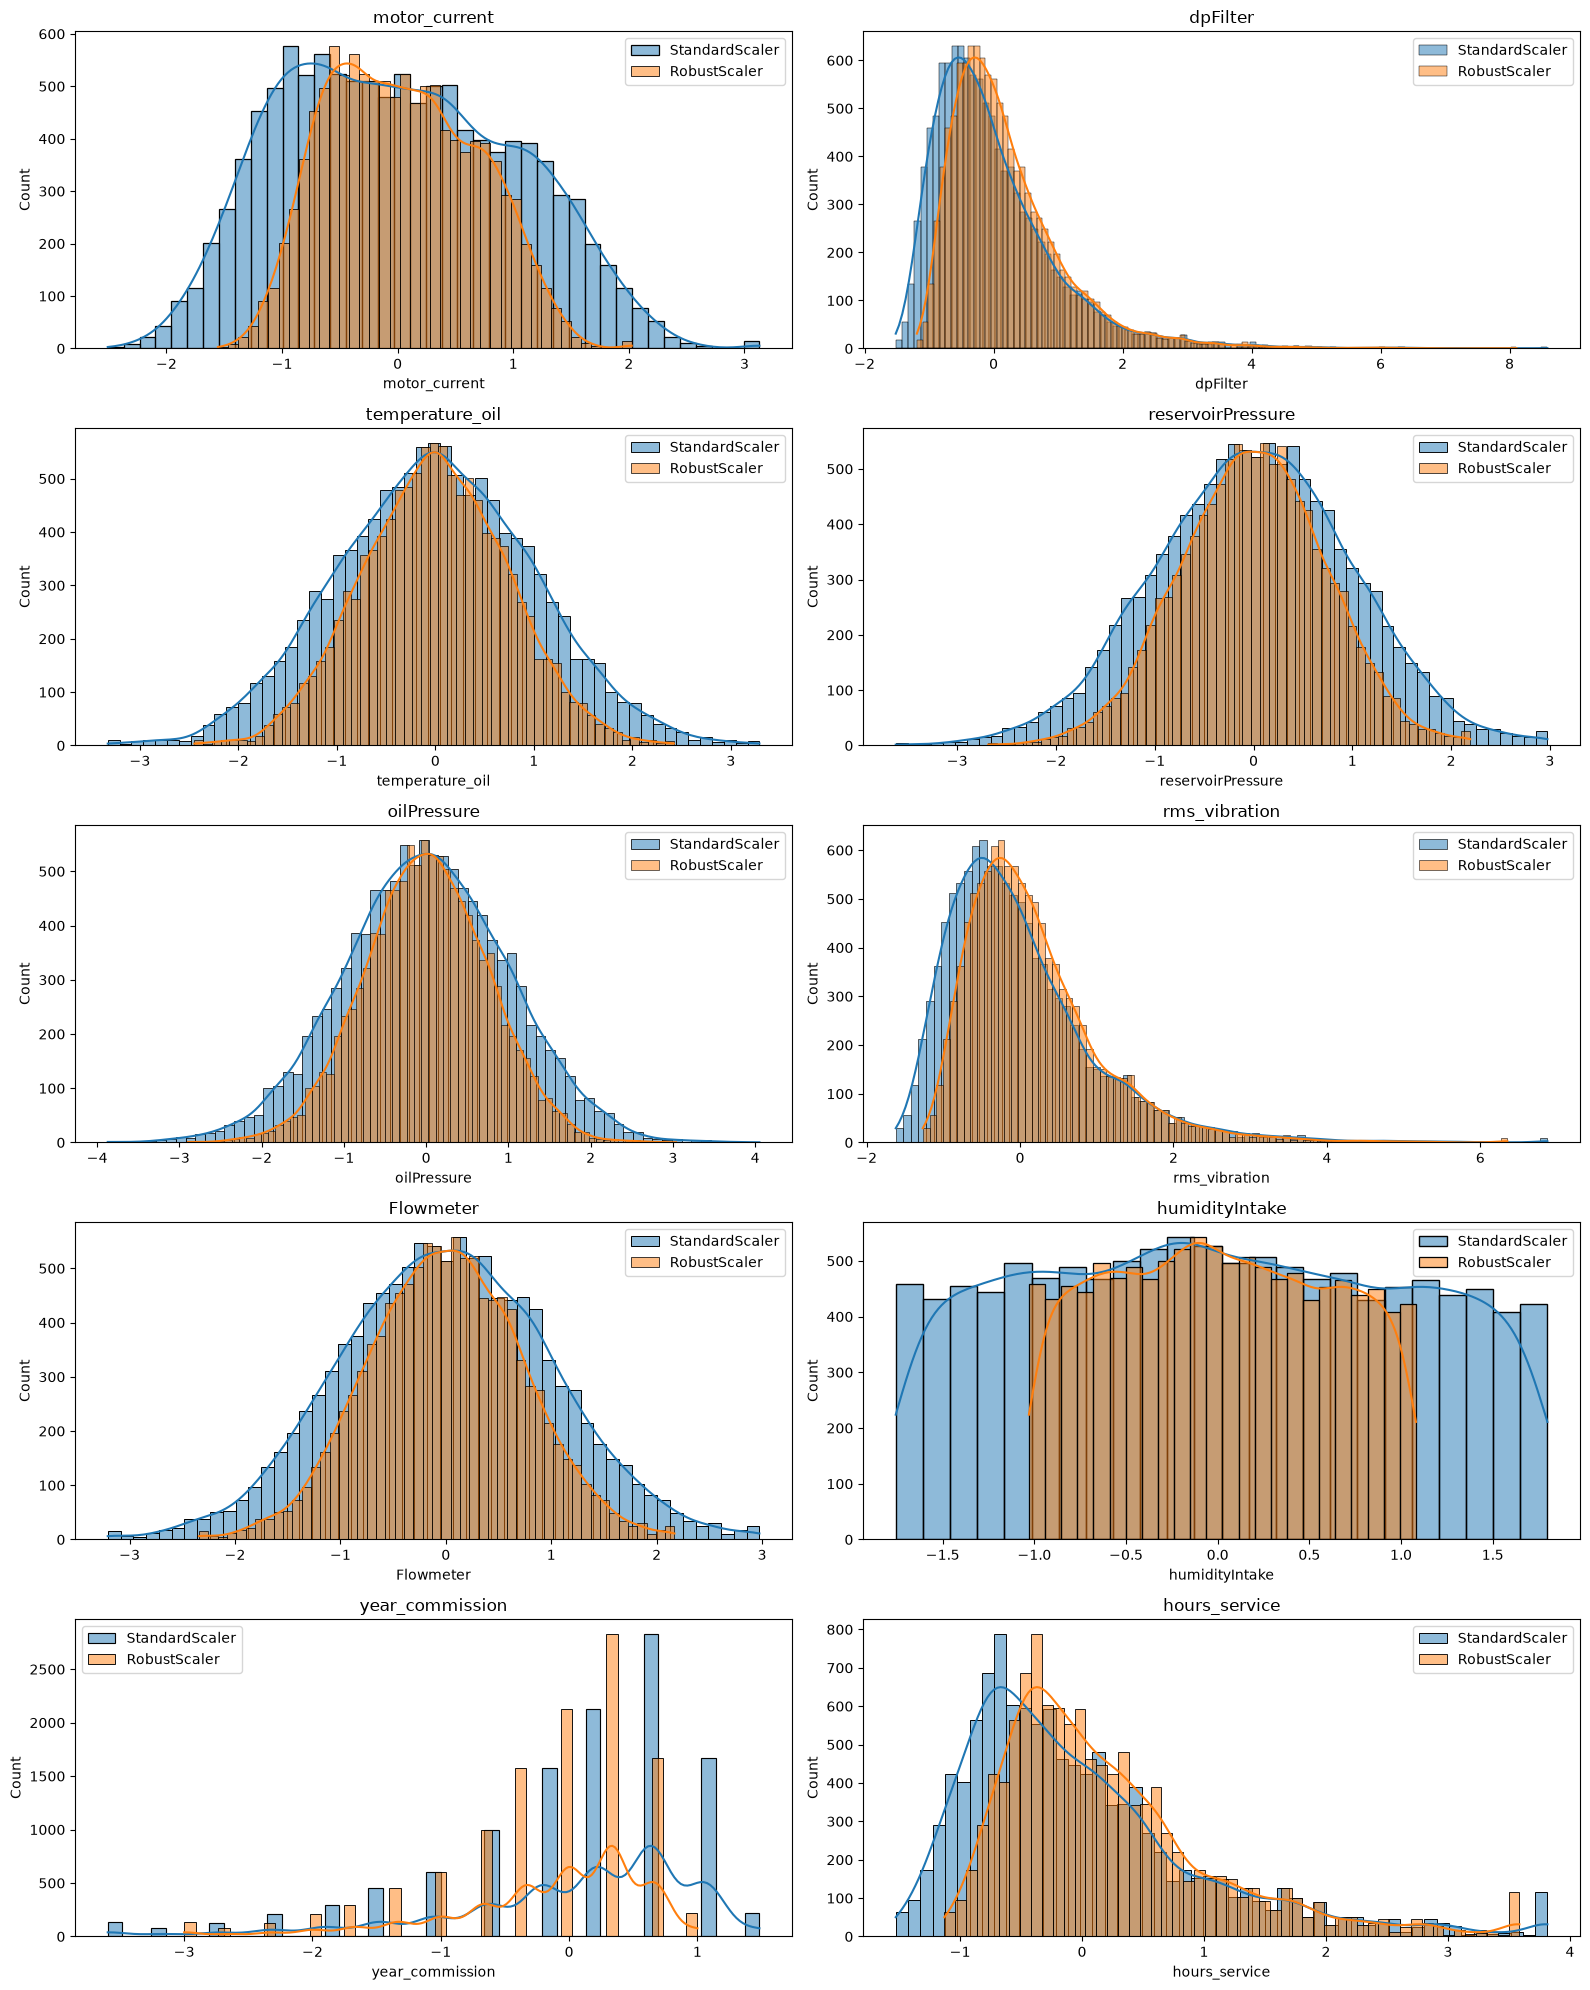

In [12]:

scaled_cols = [col for col in train_df.columns if col not in ["id_unit", "failure", "dutyClass", "version_firmware_1", "version_firmware_2", "version_firmware_3"]]

scaler = sklearn.preprocessing.StandardScaler()
standard_scaled = train_df.copy()
standard_scaled[scaled_cols] = scaler.fit_transform(train_df[scaled_cols])


scaler = sklearn.preprocessing.RobustScaler()
robust_scaled = train_df.copy()
robust_scaled[scaled_cols] = scaler.fit_transform(train_df[scaled_cols])


fig, axs = plt.subplots(5, 2, figsize=(16, 20))
axs = axs.ravel()

for ax, column in zip(axs, scaled_cols):
    sns.histplot(standard_scaled[column], ax=ax, kde=True, label="StandardScaler")
    sns.histplot(robust_scaled[column], ax=ax, kde=True, label="RobustScaler")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Count")
    ax.legend()
fig.tight_layout()
plt.show()


Škálovanie obomi spôsobmi prinieslo podobné výsledky, z ktorých nevieme povedať či jeden Scaler je lepší než druhý, no **RobustScaler** má o čosi užší rozsah hodnôt a preto asi budeme pokračovať s ním.

### Transformovanie pomocou transformerov

Porovnáme PowerTransformer Yeo-Johnson a QuantileTransformer, pretože Box-Cox vie pracovať len s kladnými hodnotami a naše atribúty sú po škálovaní aj záporné.

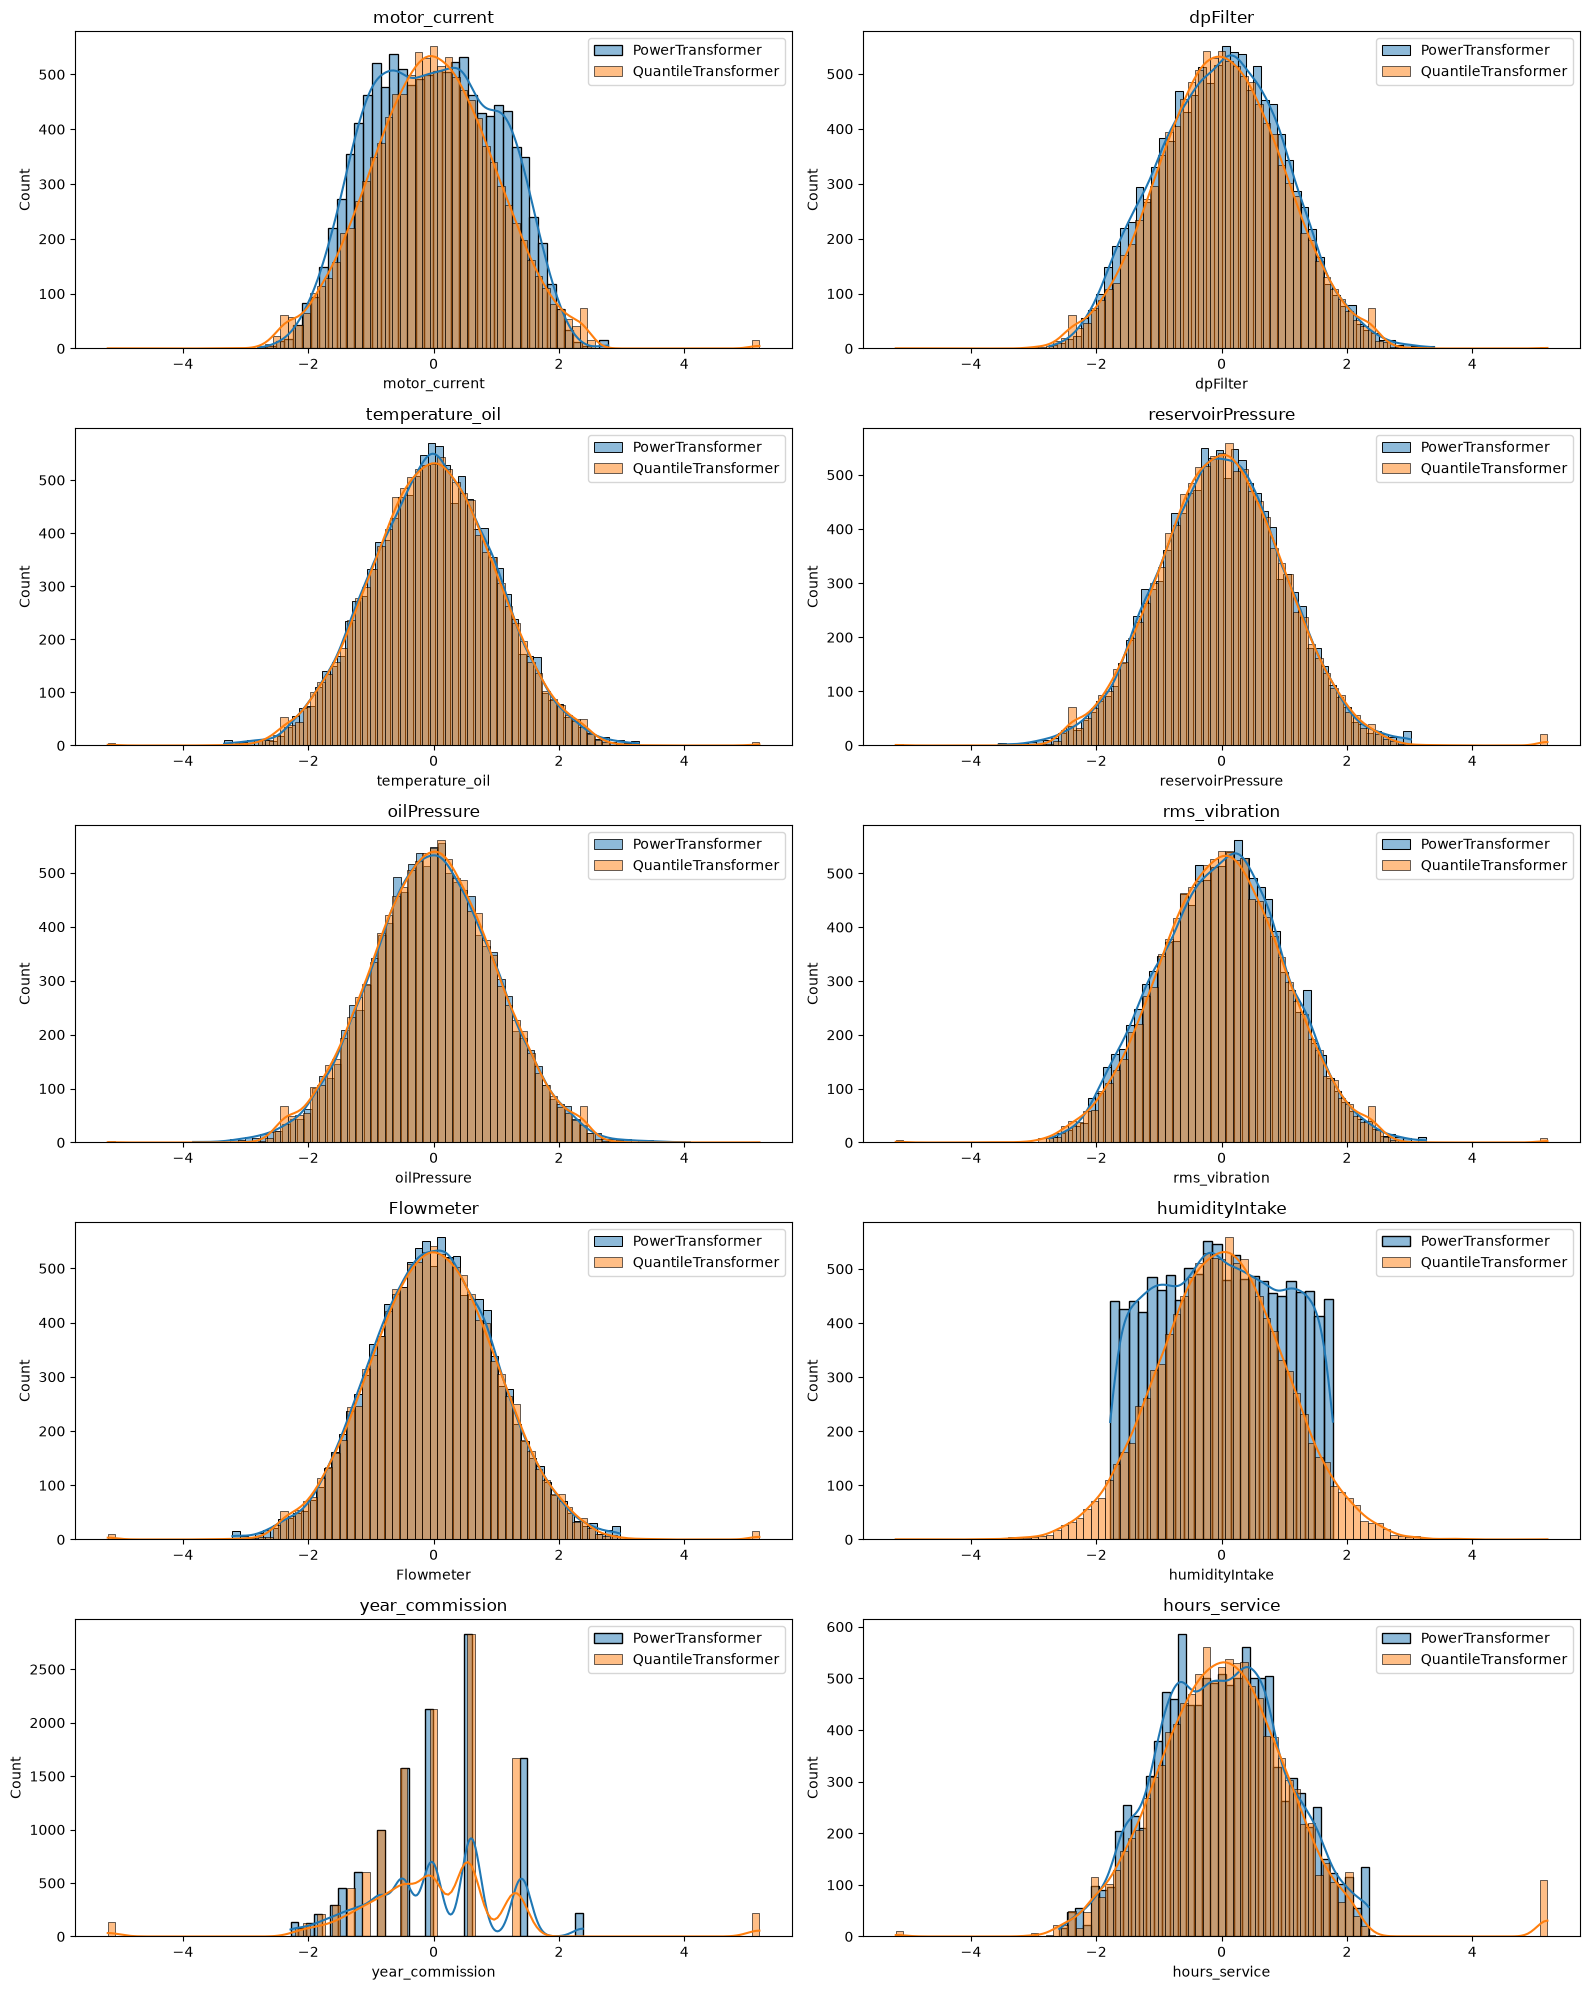

In [13]:
transformed_cols = [col for col in train_df.columns if col not in ["id_unit", "failure", "dutyClass", "version_firmware_1", "version_firmware_2", "version_firmware_3"]]


power = sklearn.preprocessing.PowerTransformer(method='yeo-johnson', standardize=True) 
power_transformed = robust_scaled.copy()
power_transformed[transformed_cols] = power.fit_transform(robust_scaled[transformed_cols])


quantile = sklearn.preprocessing.QuantileTransformer(n_quantiles=100, output_distribution="normal", random_state=0) 
quantile_transformed = robust_scaled.copy()
quantile_transformed[transformed_cols] = quantile.fit_transform(robust_scaled[transformed_cols])


fig, axs = plt.subplots(5, 2, figsize=(16, 20))
axs = axs.ravel()

for ax, column in zip(axs, transformed_cols):
    sns.histplot(power_transformed[column], ax=ax, kde=True, label="PowerTransformer")
    sns.histplot(quantile_transformed[column], ax=ax, kde=True, label="QuantileTransformer")
    ax.set_title(column)
    ax.set_xlabel(column)
    ax.set_ylabel("Count")
    ax.legend()
fig.tight_layout()
plt.show()

Porovnanie výsledkov PowerTransformera a QuantileTransformera je trochu neisté, pretože síce gausovo rozloženie na výstupe z QuantileTransformera vyzerá lákavo, obávame sa toho, že transformácia bola príliš agresívna a pre dosiahnutie perfektného zvonu by sme možno stratili prirodzenú výpovednú hodnotu našich dát. PowerTransform ponúka tiež veľmi elegantné výsledky s distribúciou blízkou gausovej, no keďže nepristupuje k transformácii tak agresívne, mal by lepšie zachovať vzťahy v dátach.

#### Overenie cez kvalitatívne metriky

In [14]:
pd.DataFrame({
    'original_skew': train_df[attributes].apply(stats.skew).round(3),
    'power_skew': power_transformed[attributes].apply(stats.skew).round(3),
    'quantile_skew': quantile_transformed[attributes].apply(stats.skew).round(3),

    'original_kurtosis': train_df[attributes].apply(stats.kurtosis).round(3),
    'power_kurtosis': power_transformed[attributes].apply(stats.kurtosis).round(3),
    'quantile_kurtosis': quantile_transformed[attributes].apply(stats.kurtosis).round(3),

    'original_mean': train_df[attributes].mean().round(3),
    'power_mean': power_transformed[attributes].mean().round(3),
    'quantile_mean': quantile_transformed[attributes].mean().round(3),

    'original_std': train_df[attributes].std().round(3),
    'power_std': power_transformed[attributes].std().round(3),
    'quantile_std': quantile_transformed[attributes].std().round(3),
})

,original_skew,power_skew,quantile_skew,original_kurtosis,power_kurtosis,quantile_kurtosis,original_mean,power_mean,quantile_mean,original_std,power_std,quantile_std
motor_current,0.204,0.015,0.142,-0.742,-0.802,0.545,5.221,0.0,-0.002,1.832,1.0,1.002
dpFilter,2.035,0.046,0.028,7.600,-0.357,-0.019,24.064,-0.0,-0.002,11.173,1.0,0.990
temperature_oil,0.012,0.001,0.022,-0.064,-0.064,0.302,55.217,-0.0,-0.001,12.092,1.0,1.002
reservoirPressure,-0.036,0.000,0.193,-0.004,-0.007,0.987,8.696,0.0,0.001,0.606,1.0,1.010
oilPressure,-0.021,-0.003,-0.015,0.073,0.072,-0.090,3.699,0.0,-0.006,0.568,1.0,0.987
rms_vibration,1.700,0.034,0.033,5.069,-0.277,0.459,3.075,0.0,0.002,1.589,1.0,1.005
Flowmeter,0.001,-0.002,0.054,-0.046,-0.046,1.098,27.969,-0.0,0.005,4.045,1.0,1.019
humidityIntake,0.031,0.003,0.008,-1.133,-1.134,0.080,51.993,-0.0,0.002,23.911,1.0,1.001
year_commission,-1.298,-0.043,0.441,1.715,-0.464,6.621,2020.495,0.0,0.010,2.363,1.0,1.261
hours_service,1.402,0.046,0.768,2.202,-0.476,3.898,13972.941,-0.0,0.025,8132.412,1.0,1.093


Tabuľkou vyššie sme si chceli numericky vyjadriť pozorovania z grafov. Sledujeme hlavne ako sa mení skew a kurtosis pred a po transformácii, zatiaľ čo mean a štandardná odchylka sú tam len pre zaujímavosť.  
Z výsledkov by sme mohli povedať, že u väčšiny atribútov boli hodnoty skew a kurtosis dosť blízko normálnemu rozloženiu už pred transformovaním Transformerom. PowerTransformer takmer všetky atribúty ešte o čosi viac priblížil gausovej krivke, zatiaľ čo QuantileTransformer si pri niektorých atribútoch aj pohoršil.  
Definitívne si teda volíme PowerTransformer s yeo-johnson metódou do nášho pipelinu.   
**Sad Optimus Prime Noises*

In [15]:
x = power_transformed.drop(['failure', 'id_unit'], axis=1)
y = power_transformed['failure']

In [ ]:
from sklearn.feature_selection import mutual_info_classif
  
def mutual_info_c(x, y):   
    selector = mutual_info_classif(x, y)
    scores = pd.Series(selector, index=x.columns).sort_values()

    return scores.sort_values(ascending=False)

mic_out = mutual_info_c(x, y)
print (mic_out)

year_commission       0.011164
hours_service         0.010439
dutyClass             0.007092
motor_current         0.006196
oilPressure           0.005369
version_firmware_1    0.004776
Flowmeter             0.004105
dpFilter              0.003389
version_firmware_2    0.003177
version_firmware_3    0.001190
temperature_oil       0.001078
humidityIntake        0.000000
reservoirPressure     0.000000
rms_vibration         0.000000
dtype: float64


In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression

estimator = LogisticRegression(class_weight='balanced')
selector = RFE(estimator, n_features_to_select=1, step=1)
selector = selector.fit(x, y)

print(selector.ranking_)

cols = x.columns
ranks = selector.ranking_
rfe_out = ["" for _ in range(len(cols))]
for attribute, n in zip(cols, ranks):
    rfe_out[n-1] = attribute

print (rfe_out)

[ 2  7 14  8 13 10 11 12  9  1  6  3  4  5]
['dutyClass', 'motor_current', 'version_firmware_1', 'version_firmware_2', 'version_firmware_3', 'hours_service', 'dpFilter', 'reservoirPressure', 'year_commission', 'rms_vibration', 'Flowmeter', 'humidityIntake', 'oilPressure', 'temperature_oil']


In [27]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(random_state=0)
clf = clf.fit(x, y)
clf.feature_importances_

rfc_out = pd.Series(clf.feature_importances_, index=x.columns).sort_values(ascending=False)
print(rfc_out)



motor_current         0.120924
dpFilter              0.109576
temperature_oil       0.107489
reservoirPressure     0.102152
hours_service         0.101835
rms_vibration         0.098230
oilPressure           0.096757
humidityIntake        0.095929
Flowmeter             0.093402
year_commission       0.038222
dutyClass             0.016457
version_firmware_2    0.008095
version_firmware_3    0.005537
version_firmware_1    0.005396
dtype: float64


In [29]:
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LogisticRegression

selector = SelectFromModel(estimator=LogisticRegression()).fit(x, y)
sfm_lr_out = pd.Series(selector.estimator_.coef_[0], index=x.columns).sort_values(ascending=False)
sfm_lr_out = sfm_lr_out.abs().sort_values(ascending=False)
print(sfm_lr_out)


dutyClass             1.532782
motor_current         0.889215
dpFilter              0.329075
reservoirPressure     0.287464
hours_service         0.253122
version_firmware_1    0.187986
year_commission       0.187760
version_firmware_2    0.154469
rms_vibration         0.126589
Flowmeter             0.104301
version_firmware_3    0.072278
oilPressure           0.042130
humidityIntake        0.022287
temperature_oil       0.001221
dtype: float64


Koeficienty vychádzali aj záporné, napríklad pri atribúte `dutyClass`, no nezdalo sa nám, že by to mal byť najhorší atribút zo všetkých, tak po chvíli hladania sme zistili že aj záporné hodnoty sú relevantné (preto tá absolútna hodnota)